# Learning Logistic Regression with Gradient Descent

## Introduction

In this notebook, we will learn how logistic regression works and how
gradient descent helps a machine learning model learn from data.

Our goal is to predict whether a lunch is good or not using four input
features:

- Queue length
- Plate waste fraction
- Menu board calories
- Handwriting neatness

The target column is `good_lunch`:

- 1 means the lunch was good.
- 0 means the lunch was not good.

We will implement logistic regression using NumPy instead of using
a ready-made machine learning library.

### What we will learn

1. What logistic regression is.
2. Why we use the sigmoid function.
3. How binary cross-entropy measures prediction error.
4. How gradient descent updates model parameters.
5. How different learning rates affect training.
6. How to evaluate the trained model.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

print("Libraries imported successfully!")

Libraries imported successfully!


## 1. Loading the Dataset

Before training a machine learning model, we need data.

We will load the binary classification dataset using Pandas.

Each row represents one lunch observation. The first four columns
are input features, while `good_lunch` is the value we want to predict.

In [2]:
ROOT = Path.cwd().parents[1]

DATA_PATH = ROOT / "datasets" / "binary_classification.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)

df.head()

Dataset shape: (500, 5)


,queue_length,plate_waste_fraction,menu_board_kcal,handwriting_neatness,good_lunch
0,43,0.575,2096,8.2,0
1,37,0.497,1924,5.2,0
2,43,0.348,2280,7.7,1
3,35,0.812,2015,4.8,0
4,28,0.377,2492,9.2,0


## 2. Understanding the Dataset

Our dataset contains four input features and one target column.

Before training, we should inspect the data and check for missing values.

In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
print(df.info())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["good_lunch"].value_counts())

Column names:
['queue_length', 'plate_waste_fraction', 'menu_board_kcal', 'handwriting_neatness', 'good_lunch']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   queue_length          500 non-null    int64  
 1   plate_waste_fraction  500 non-null    float64
 2   menu_board_kcal       500 non-null    int64  
 3   handwriting_neatness  500 non-null    float64
 4   good_lunch            500 non-null    int64  
dtypes: float64(2), int64(3)
memory usage: 19.7 KB
None

Missing values:
queue_length            0
plate_waste_fraction    0
menu_board_kcal         0
handwriting_neatness    0
good_lunch              0
dtype: int64

Target distribution:
good_lunch
0    296
1    204
Name: count, dtype: int64


## 3. Preparing the Data

We separate the dataset into:

- Features (X): information used to make predictions.
- Target (y): the actual result we want to predict.

We use 80% of the data for training and 20% for testing.

A fixed random seed makes the split reproducible.

We also standardize the input features. This puts them on comparable
scales, helping gradient descent train more effectively.

In [4]:
FEATURES = [
    "queue_length",
    "plate_waste_fraction",
    "menu_board_kcal",
    "handwriting_neatness"
]

TARGET = "good_lunch"

X = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=float)

# Reproducible 80/20 split
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Standardize using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])

Training samples: 400
Testing samples: 100
Number of features: 4


FEATURES = [
    "queue_length",
    "plate_waste_fraction",
    "menu_board_kcal",
    "handwriting_neatness"
]

TARGET = "good_lunch"

X = df[FEATURES].to_numpy(dtype=float)
y = df[TARGET].to_numpy(dtype=float)

# Reproducible 80/20 split
rng = np.random.default_rng(42)
indices = rng.permutation(len(X))

split = int(0.8 * len(X))

train_idx = indices[:split]
test_idx = indices[split:]

X_train = X[train_idx]
X_test = X[test_idx]

y_train = y[train_idx]
y_test = y[test_idx]

# Standardize using training data only
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

std[std == 0] = 1

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of features:", X_train.shape[1])

In [5]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

values = np.array([-4, -2, 0, 2, 4])

print("Input:", values)
print("Sigmoid output:", sigmoid(values))

Input: [-4 -2  0  2  4]
Sigmoid output: [0.01798621 0.11920292 0.5        0.88079708 0.98201379]


### Visualizing the Sigmoid Function

The sigmoid function converts any real-valued input into a value
between 0 and 1.

This makes it useful for binary classification.

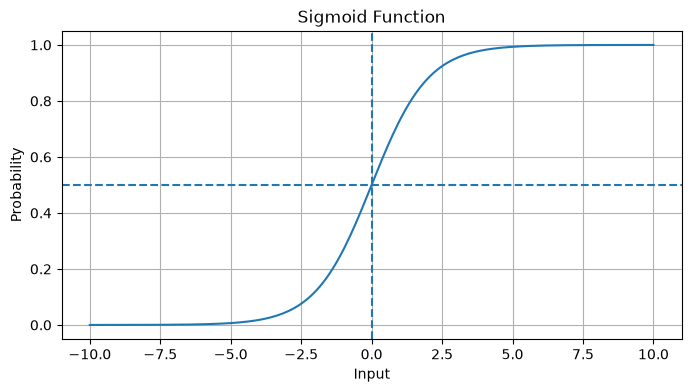

In [6]:
z = np.linspace(-10, 10, 200)

plt.figure(figsize=(8, 4))
plt.plot(z, sigmoid(z))
plt.axhline(0.5, linestyle="--")
plt.axvline(0, linestyle="--")

plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid(True)
plt.show()

## 5. Binary Cross-Entropy Loss

A machine learning model needs a way to measure how wrong its
predictions are.

For binary classification, we use binary cross-entropy loss.

A lower loss means the predicted probabilities are closer to
the actual labels.

The model tries to minimize this loss during training.

In [7]:
def binary_cross_entropy(y, probabilities):
    eps = 1e-12
    probabilities = np.clip(probabilities, eps, 1 - eps)

    loss = -np.mean(
        y * np.log(probabilities)
        + (1 - y) * np.log(1 - probabilities)
    )

    return loss


sample_actual = np.array([1, 0, 1])
sample_predictions = np.array([0.9, 0.2, 0.6])

print(
    "Example loss:",
    binary_cross_entropy(sample_actual, sample_predictions)
)

Example loss: 0.2797765635793423


## 6. Gradient Descent

Gradient descent is an optimization algorithm used to minimize
the model's loss.

It works by repeatedly:

1. Making predictions.
2. Calculating the prediction errors.
3. Calculating gradients.
4. Updating weights and bias.
5. Repeating until the model converges or reaches the epoch limit.

The learning rate controls how large each update is.

A very small learning rate can make training slow. A very large
learning rate can make training unstable.

In [8]:
def train_model(X, y, learning_rate, epochs=10000,
                tolerance=1e-9, patience=20):

    weights = np.zeros(X.shape[1])
    bias = 0.0

    losses = []
    stable_epochs = 0
    converged = False

    for epoch in range(epochs):

        # Step 1: Make predictions
        probabilities = sigmoid(X @ weights + bias)

        # Step 2: Calculate loss
        loss = binary_cross_entropy(y, probabilities)
        losses.append(loss)

        # Step 3: Calculate gradients
        error = probabilities - y

        dw = (X.T @ error) / len(y)
        db = np.mean(error)

        # Step 4: Update parameters
        weights -= learning_rate * dw
        bias -= learning_rate * db

        # Step 5: Check convergence
        if len(losses) > 1:
            if abs(losses[-2] - losses[-1]) < tolerance:
                stable_epochs += 1
            else:
                stable_epochs = 0

        if stable_epochs >= patience:
            converged = True
            break

    return weights, bias, losses, epoch + 1, converged


print("Gradient descent function is ready!")

Gradient descent function is ready!


## 7. Training with Different Learning Rates

We will train three logistic regression models using:

- 0.001
- 0.05
- 0.5

We will compare their accuracy, number of epochs, final loss
and convergence behaviour.

In [9]:
def predict(X, weights, bias):
    probabilities = sigmoid(X @ weights + bias)
    return (probabilities >= 0.5).astype(int)


learning_rates = [0.001, 0.05, 0.5]

results = {}

for lr in learning_rates:

    weights, bias, losses, epochs, converged = train_model(
        X_train, y_train, lr
    )

    predictions = predict(X_test, weights, bias)

    accuracy = np.mean(predictions == y_test) * 100

    results[lr] = {
        "weights": weights,
        "bias": bias,
        "losses": losses,
        "epochs": epochs,
        "converged": converged,
        "accuracy": accuracy
    }

    print(f"\nLearning rate: {lr}")
    print(f"Accuracy: {accuracy:.2f}%")
    print(f"Epochs: {epochs}")
    print(f"Converged: {converged}")
    print(f"Final loss: {losses[-1]:.6f}")


Learning rate: 0.001
Accuracy: 82.00%
Epochs: 10000
Converged: False
Final loss: 0.423337

Learning rate: 0.05
Accuracy: 82.00%
Epochs: 2334
Converged: True
Final loss: 0.401479

Learning rate: 0.5
Accuracy: 82.00%
Epochs: 294
Converged: True
Final loss: 0.401478


## 8. Comparing Loss Curves

A loss curve shows how the model's loss changes during training.

We can use these curves to compare how quickly different learning
rates converge.

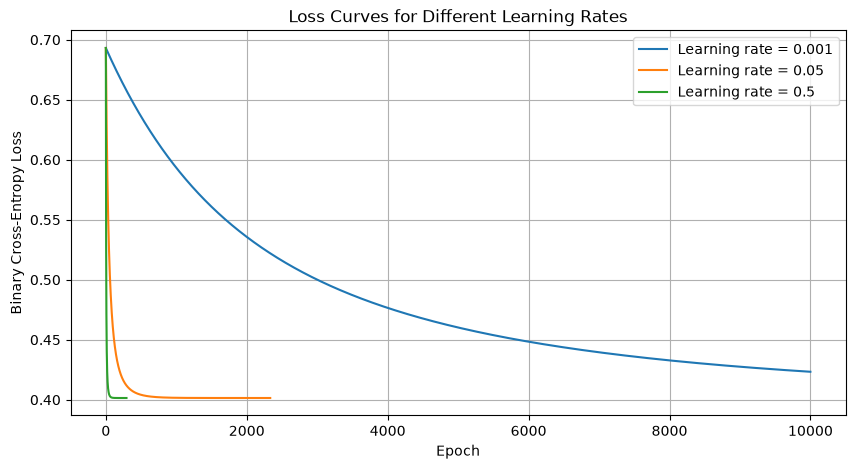

In [10]:
plt.figure(figsize=(10, 5))

for lr, result in results.items():
    plt.plot(
        result["losses"],
        label=f"Learning rate = {lr}"
    )

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("Loss Curves for Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

## 9. Conclusion

In this notebook, we implemented logistic regression using NumPy
and trained it using gradient descent.

The experiment showed that:

- Logistic regression can be used for binary classification.
- The sigmoid function converts raw model outputs into probabilities.
- Binary cross-entropy measures prediction error.
- Gradient descent updates model parameters to reduce loss.
- Learning rate has a major impact on training speed.
- Different learning rates can achieve the same test accuracy
  while requiring different numbers of epochs.

In our experiment, all three learning rates achieved 82% test accuracy.

The learning rate of 0.5 converged in 294 epochs, while 0.05
converged in 2,334 epochs. The learning rate of 0.001 did not
converge within the 10,000-epoch limit.

This demonstrates why choosing an appropriate learning rate
is important when training machine learning models.